# SECOM: what does a useful failure detector actually learn?

My investigation of missing sensors, rare failures, and the gap between ranking observations and deciding which ones to flag. This is supervised classification on [UCI SECOM](https://doi.org/10.24432/C54305), despite the repository's anomaly-detection name.

**Start here:** run this notebook from the repository root with the Python 3.12 `.venv`. If `results/metrics.json`, the prediction exports, or current figures are absent, first run **`uv run python main.py`** and let it finish. Then run **`uv run python scripts/execute_notebook.py`** to execute this notebook and save its outputs for GitHub readers. The runner needs the declared development dependencies (`uv sync --group dev`). No extra IPython extension is required.

The notebook reads the saved experiment; it does not train the seven candidates again. Its only preprocessing fit is a small, development-only `SensorFilter` demonstration. All performance tables are checked against saved row-level predictions. The four embedded figures are generated by the study, rather than redrawn from historical results.

In [1]:
import json
import sys
from hashlib import sha256
from importlib.metadata import version
from pathlib import Path

ROOT = Path.cwd().resolve()
assert (ROOT / 'secom' / 'experiment.py').is_file(), 'Use the repository root as the notebook working directory.'
assert sys.version_info[:2] == (3, 12), 'Use the repository Python 3.12 environment.'
RESULTS = ROOT / 'results'
required_results = [
    'metrics.json', 'protocol.json', 'development_metrics.csv', 'holdout_metrics.csv',
    'fold_metrics.csv', 'split_manifest.csv', 'oof_predictions.csv',
    'holdout_predictions.csv', 'feature_importance.csv', 'data_quality.csv', 'RESULTS.md',
]
FIGURES = ['missingness.png', 'pca_variance_comparison.png', 'pr_curve.png', 'confusion_matrix.png']
required_paths = [RESULTS / name for name in required_results]
required_paths += [ROOT / 'images' / name for name in FIGURES]
required_paths += [ROOT / 'data' / 'raw' / name for name in ('secom.data', 'secom_labels.data')]
missing_paths = [str(path.relative_to(ROOT)) for path in required_paths if not path.is_file()]
if missing_paths:
    raise FileNotFoundError(
        'Complete experiment artifacts are required. Run `uv run python main.py` first and let it finish. '
        'Missing: ' + ', '.join(missing_paths)
    )

import numpy as np
import pandas as pd
from IPython.display import Image as IPythonImage
from IPython.display import Markdown, display
from scipy.stats import norm
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score, confusion_matrix,
    f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score,
)

from secom.data import CHECKSUMS, load_dataset
from secom.modeling import CANDIDATES, LABELS, SensorFilter

pd.set_option('display.max_columns', 14)
pd.set_option('display.precision', 5)
print('Complete saved artifacts found. This notebook will audit them without refitting the study.')

Complete saved artifacts found. This notebook will audit them without refitting the study.


## 1. The question I wanted to keep

The original project started with a useful puzzle: how can a classifier look accurate while catching almost no failing observations? I kept its sequence of questions: remove sparse and constant sensors, compare median with KNN imputation, inspect PCA, try SMOTE, try weighted boosting, and examine the threshold.

I also had to change what counted as evidence. The earlier notebook filtered sensors before splitting, fitted a separate test scaler in its median branch, used raw-unit distances for KNN, and selected the XGBoost threshold from the same test labels used to report F1. Its PR figure used trapezoidal integration. Those outputs describe the earlier exploration, not the evaluation below. Correcting those choices does not guarantee a better score.

**I had already explored this dataset.** The new holdout is excluded from fitting and selection within this run; it is not historically unseen data. I cannot turn the revision into a preregistered or independent discovery by changing the seed. The [experiment protocol](docs/11_experiment_protocol.md) defines the current boundary, and the [project journal](docs/12_project_journal.md) records the original decisions.

## 2. The comparison contract

1. Reserve a stratified 20% holdout with seed 2026. Explore sensor distributions only on the remaining development rows. Timestamps are metadata, never predictors.
2. Compare seven fixed pipelines on the same five shuffled, stratified development folds. Every learned mask, scaler, imputer, PCA transform, sampler, and class weight belongs to that fold's training rows.
3. Select the candidate with the largest **mean fold average precision (AP)**. Resolve exact ties in the saved candidate order. Separately select each candidate's maximum-F1 threshold from its **pooled out-of-fold (OOF)** development predictions; choose the highest threshold on exact ties.
4. Freeze that choice and all seven thresholds before scoring the holdout. Refit each pipeline on development, evaluate all seven for audit, and retain the development-selected candidate even if the holdout ordering changes.

AP here is `average_precision_score`: a recall-weighted sum of precisions, **not trapezoidal area under a PR curve**. Mean fold AP and pooled OOF AP are different summaries. Precision, recall, F1, and confusion counts also require a threshold. A score of 0.5 is a diagnostic reference; class weighting and resampling do not produce calibrated failure probabilities. F1 encodes no measured factory cost.

In [2]:
metrics = json.loads((RESULTS / 'metrics.json').read_text())
protocol_bytes = (RESULTS / 'protocol.json').read_bytes()
protocol = json.loads(protocol_bytes)
assert metrics['schema_version'] == protocol['schema_version'] == 1
assert sha256(protocol_bytes).hexdigest() == metrics['protocol_sha256']
assert metrics['source_sha256'] == protocol['source_sha256']
assert metrics['config'] == protocol['config']
assert protocol['config']['seed'] == 2026
assert protocol['config']['folds'] == 5
assert protocol['config']['test_fraction'] == 0.2
assert protocol['candidates_in_tie_break_order'] == list(CANDIDATES)
assert set(protocol['thresholds']) == set(CANDIDATES)
assert pd.Timestamp(metrics['started_at_utc']) <= pd.Timestamp(protocol['frozen_at_utc']) <= pd.Timestamp(metrics['completed_at_utc'])

# Match the ordered source digest used by run_study; the notebook is not a study input.
source_files = [ROOT / 'main.py', ROOT / 'pyproject.toml', ROOT / 'uv.lock', *sorted((ROOT / 'secom').glob('*.py'))]
source_digest = sha256()
for path in source_files:
    source_digest.update(path.relative_to(ROOT).as_posix().encode())
    source_digest.update(path.read_bytes())
assert source_digest.hexdigest() == metrics['source_sha256'], 'Study source differs from this run; regenerate a consistent set of results.'

def read_table(name):
    # Preserve threshold-boundary comparisons when reading saved floating-point scores.
    return pd.read_csv(RESULTS / name, float_precision='round_trip')

development_metrics = read_table('development_metrics.csv').set_index('candidate').loc[list(CANDIDATES)]
fold_metrics = read_table('fold_metrics.csv')
split = read_table('split_manifest.csv')
oof = read_table('oof_predictions.csv')
quality = read_table('data_quality.csv').set_index('sensor')
importance = read_table('feature_importance.csv')

display(pd.Series({
    'run started (UTC)': metrics['started_at_utc'],
    'protocol frozen (UTC)': protocol['frozen_at_utc'],
    'run completed (UTC)': metrics['completed_at_utc'],
    'study source SHA-256': metrics['source_sha256'],
    'protocol SHA-256': metrics['protocol_sha256'],
}, name='Saved provenance').to_frame())
display(pd.Series(protocol['config'], name='Actual run configuration').to_frame())
environment_rows = [{'package': 'python', 'saved': metrics['environment']['python'], 'current': sys.version.split()[0]}]
for package, saved_version in metrics['environment'].items():
    if package not in {'python', 'platform'}:
        environment_rows.append({'package': package, 'saved': saved_version, 'current': version(package)})
environment = pd.DataFrame(environment_rows).set_index('package')
environment['matches'] = environment['saved'] == environment['current']
display(environment)
print('Hash checks bind the saved protocol and current study source. They do not prove historical independence or preregistration.')

,Saved provenance
run started (UTC),2026-11-02T20:29:09.461210+00:00
protocol frozen (UTC),2026-11-02T20:30:56.257434+00:00
run completed (UTC),2026-11-02T20:32:51.977499+00:00
study source SHA-256,c12ae2d547002062f2f93e6d613b5c2cf3f902ff7c4b8a...
protocol SHA-256,58e210ccd360a7de16b5f77c5be029e3888f96232e9bfd...


,Actual run configuration
seed,2026
folds,5
trees,300
jobs,2
bootstrap,2000
temporal_check,True
test_fraction,0.2


,saved,current,matches
package,,,
python,3.12.13,3.12.13,True
numpy,2.5.4,2.5.4,True
pandas,2.3.3,2.3.3,True
scipy,1.18.1,1.18.1,True
scikit-learn,1.7.2,1.7.2,True
imbalanced-learn,0.14.2,0.14.2,True
xgboost,3.4.1,3.4.1,True
matplotlib,3.11.2,3.11.2,True
joblib,1.6.0,1.6.0,True


Hash checks bind the saved protocol and current study source. They do not prove historical independence or preregistration.


## 3. Validate identity before exploring distributions

The published data contract is 1,567 observations, 590 anonymous sensor columns, 1,463 passes, and 104 failures. The loader verifies both cached raw files against pinned SHA-256 references, checks dimensions and labels, rejects infinite sensor values, maps raw labels -1/+1 to 0/1, and parses timestamps separately. The data source is UCI SECOM, attributed as CC BY 4.0.

I recover row membership from the saved split rather than quietly creating another split. Checking source labels and row identity is a data-contract check. The exploratory class balance, missingness, distinct-value counts, and sensor-mask fit below all use **development rows only**. I do not inspect holdout sensor distributions.

In [3]:
dataset = load_dataset(ROOT / 'data' / 'raw')
assert dataset.X.shape == (1567, 590)
assert set(dataset.y) == {0, 1}
assert dataset.manifest['sha256'] == CHECKSUMS == metrics['dataset']['sha256']
assert dataset.X.columns.tolist() == [f'sensor_{index:03d}' for index in range(590)]
assert not split['row_id'].duplicated().any()
assert set(split['row_id']) == set(range(len(dataset.y)))
assert set(split['partition']) == {'development', 'holdout'}
split = split.set_index('row_id').sort_index()
np.testing.assert_array_equal(split['label'].to_numpy(), dataset.y)
np.testing.assert_array_equal(pd.to_datetime(split['timestamp']).to_numpy(), dataset.timestamps.to_numpy())
dev_manifest = split.loc[split['partition'].eq('development')]
holdout_manifest = split.loc[split['partition'].eq('holdout')]
development_ids = dev_manifest.index.to_numpy()
holdout_ids = holdout_manifest.index.to_numpy()
assert not np.intersect1d(development_ids, holdout_ids).size
assert set(dev_manifest['validation_fold']) == set(range(5))
assert holdout_manifest['validation_fold'].eq(-1).all()
assert len(development_ids) == metrics['development_rows']
assert len(holdout_ids) == metrics['holdout_rows']
X_dev = dataset.X.iloc[development_ids]
y_dev = dataset.y[development_ids]
assert int(y_dev.sum()) == metrics['development_failures']
display(pd.Series(dataset.manifest['sha256'], name='Validated raw-file SHA-256').to_frame())
print(f'Source shape and identity validated; {len(development_ids)} development rows are available for exploration.')

,Validated raw-file SHA-256
secom.data,20f0e7ee434f7dcbae0eea9ffff009a2b57f42d6b0dc9a...
secom_labels.data,126884cf453705c9e61a903fe906f0665a3b45ce3639e6...


Source shape and identity validated; 1253 development rows are available for exploration.


In [4]:
class_counts = pd.Series(y_dev).value_counts().reindex([0, 1], fill_value=0)
class_balance = pd.DataFrame({'observations': class_counts, 'fraction': class_counts / len(y_dev)})
class_balance.index = ['Pass (0)', 'Fail (1)']
display(class_balance)
fold_support = dev_manifest.groupby('validation_fold')['label'].agg(rows='size', failures='sum')
fold_support['passes'] = fold_support['rows'] - fold_support['failures']
fold_support['failure_prevalence'] = fold_support['failures'] / fold_support['rows']
display(fold_support)
display(Markdown(
    f'On development, predicting every observation as a pass would give **{1 - y_dev.mean():.2%} accuracy** '
    f'and **zero failure recall**. The failure prevalence is **{y_dev.mean():.2%}**. '
    'That is why accuracy is a context metric rather than my selection rule.'
))

,observations,fraction
Pass (0),1170,0.93376
Fail (1),83,0.06624


,rows,failures,passes,failure_prevalence
validation_fold,,,,
0,251,17,234,0.06773
1,251,17,234,0.06773
2,251,17,234,0.06773
3,250,16,234,0.06400
4,250,16,234,0.06400


On development, predicting every observation as a pass would give **93.38% accuracy** and **zero failure recall**. The failure prevalence is **6.62%**. That is why accuracy is a context metric rather than my selection rule.

### Which sensors can I even compare?

I use the declared mask: retain a sensor only if its training missing fraction is at most 0.50 and it has more than one distinct observed value. A column can fail both tests, so the rejection counts overlap. Missing measurements alone do not tell me that a physical sensor is broken.

The fit below demonstrates the rule on full development and checks `data_quality.csv`. It is **not** the mask reused for CV. The actual experiment learns the mask afresh inside each training fold; full-development refits learn their own mask before transforming the holdout.

,Development-only diagnostic
development rows,1253.00000
input sensors,590.00000
development missing-cell fraction,0.04536
entirely missing sensors,0.00000
sensors above 50% missing,28.00000
sensors with <= 1 distinct observed value,116.00000
retained sensors,446.00000
rejected sensors (union),144.00000


,development_missing_fraction,development_distinct_observed_values,retained_on_full_development
sensor_157,0.91460,102,False
sensor_158,0.91460,107,False
sensor_292,0.91460,77,False
sensor_293,0.91460,107,False
sensor_085,0.85315,90,False
sensor_220,0.85315,67,False
sensor_358,0.85315,20,False
sensor_492,0.85315,184,False
sensor_109,0.64485,91,False
sensor_110,0.64485,443,False


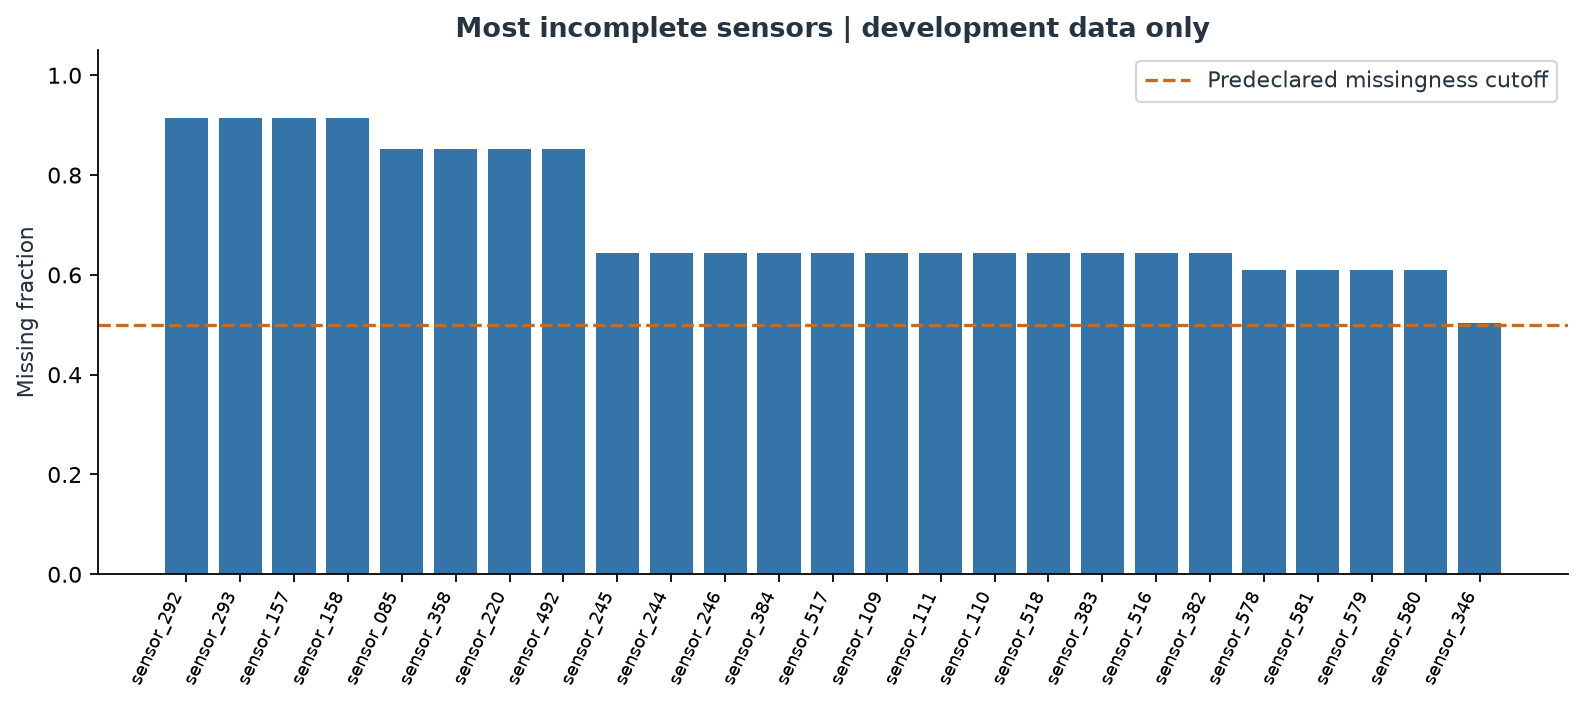

In [5]:
sensor_filter = SensorFilter(max_missing=0.5).fit(X_dev)
development_quality = pd.DataFrame({
    'development_missing_fraction': X_dev.isna().mean(),
    'development_distinct_observed_values': X_dev.nunique(dropna=True),
    'retained_on_full_development': sensor_filter.keep_mask_,
})
assert quality.index.is_unique and set(quality.index) == set(X_dev.columns)
pd.testing.assert_frame_equal(
    development_quality.rename_axis('sensor'), quality.loc[X_dev.columns].rename_axis('sensor'),
    check_exact=False, rtol=1e-10, atol=1e-12,
)
missing_fraction = development_quality['development_missing_fraction']
distinct_values = development_quality['development_distinct_observed_values']
display(pd.Series({
    'development rows': len(X_dev),
    'input sensors': X_dev.shape[1],
    'development missing-cell fraction': float(X_dev.isna().to_numpy().mean()),
    'entirely missing sensors': int(missing_fraction.eq(1).sum()),
    'sensors above 50% missing': int(missing_fraction.gt(0.5).sum()),
    'sensors with <= 1 distinct observed value': int(distinct_values.le(1).sum()),
    'retained sensors': int(sensor_filter.keep_mask_.sum()),
    'rejected sensors (union)': int((~sensor_filter.keep_mask_).sum()),
}, name='Development-only diagnostic').to_frame())
display(development_quality.sort_values('development_missing_fraction', ascending=False, kind='stable').head(10))
display(IPythonImage(filename=str(ROOT / 'images' / 'missingness.png'), width=900))

## 4. Median versus KNN: a design question before a model question

Median imputation is my simple reference: each missing entry receives its training sensor median. KNN with five uniform-weighted neighbors asks whether other observations help complete a sensor measurement. Its NaN-aware distance only compares available coordinates, so donor quality and the missingness process matter. I do not assume KNN recovers the unobserved physical value.

Both branches apply `SensorFilter -> StandardScaler -> imputer`. The scaler learns observed training values and preserves NaNs. **Scaling precedes KNN**, so a sensor's numerical units do not automatically dominate distance. The same fitted transformations apply to validation and holdout; evaluation data never fit a scaler or become an imputation donor pool. Forest split rules themselves do not require standardization; it is here for KNN geometry and a consistent comparison.

| Candidate | Completion / transformation | Estimator and purpose |
| --- | --- | --- |
| `dummy` | No sensor preprocessing | Training-prior dummy; no-skill reference |
| `logistic_median` | Median | Balanced logistic; simple supervised reference |
| `rf_median` | Median | Balanced RF; imputation reference |
| `rf_knn` | KNN | Same balanced RF; isolate the imputation change |
| `rf_knn_pca` | KNN, then learned PCA90 | Same balanced RF; test variance compression |
| `rf_knn_smote` | KNN, then training-only SMOTE | Same RF settings; test synthetic balancing |
| `xgb_knn` | KNN | Regularized XGBoost; training pass/failure weight ratio |

The default study uses 300 trees for both forest and boosting branches. Exact settings and seeds are saved in `protocol.json`; the configuration above shows the actual run. Fold `k` uses seed `2026 + k`, while full-development fits use 2026. Logistic and forest weights are balanced; after SMOTE balances the training labels, the forest's balanced weights become equal. The boosting weight is recomputed from each fit's training labels. It is an imbalance heuristic, not an estimate of business cost.

### PCA90 and SMOTE are hypotheses, not predetermined failures

**PCA hypothesis:** correlated sensors may admit a smaller representation that helps generalization. The counterargument is that low-variance directions can still carry failure signal, and rotation can change how a forest partitions the space. Retaining 90% of variance does not retain 90% of predictive information. PCA90 learns its component count within each training fold; I do not carry over the original notebook's fixed count. The generated figure below is a separate full-development variance diagnostic for median and KNN completion, not a holdout result or an imputation-accuracy test.

**SMOTE hypothesis:** training-only interpolation may help the classifier attend to rare failures. It may also create unhelpful examples if standardized neighbors do not represent meaningful process neighborhoods. The sampler operates after imputation, only on training rows; evaluation retains its observed prevalence. A result from one sampler setting cannot prove that synthetic examples are physically invalid.

I judge both hypotheses using the paired development AP comparison with `rf_knn`, and report default-threshold F1 alongside it. Zero F1 at 0.5 means no true positives at that operating point; it does not by itself establish absent ranking signal or a geometric explanation.

,retained_sensors,pca_components
fold,,
0,450,124
1,446,123
2,440,126
3,450,124
4,446,124


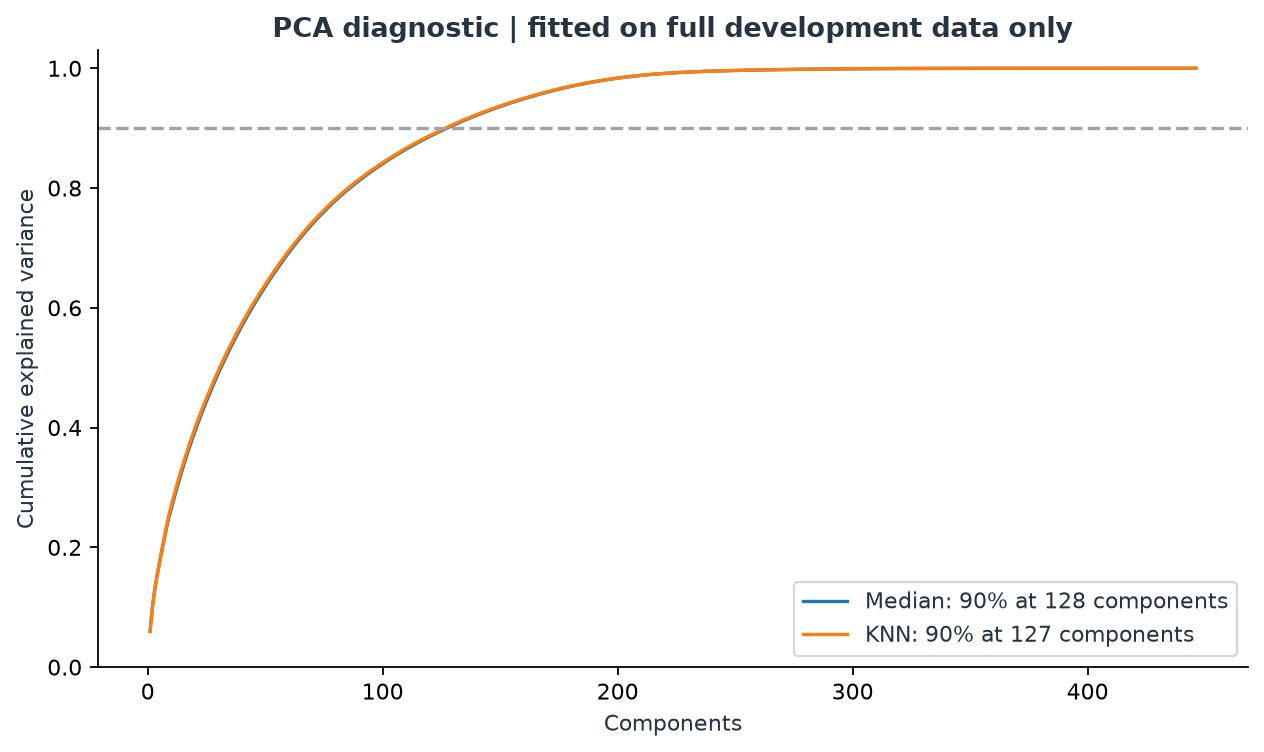

In [6]:
pca_folds = fold_metrics.loc[fold_metrics['candidate'].eq('rf_knn_pca'), ['fold', 'retained_sensors', 'pca_components']]
assert len(pca_folds) == 5
display(pca_folds.set_index('fold').astype(int))
display(IPythonImage(filename=str(ROOT / 'images' / 'pca_variance_comparison.png'), width=850))

## 5. Reconstruct the development evidence

A generated table is easier to trust when I can recover it from observations. I check one finite OOF score per development row per candidate, the same fold and label assignments, and no holdout rows in OOF. I then rebuild fold AP, fold SD, pooled AP, default F1, and the maximum-F1 threshold directly from exported predictions. Exact rational F1 comparisons preserve the highest-threshold tie rule; equality with a threshold predicts failure.

These checks recompute metrics, not fitted models. They catch inconsistent tables and exports; they do not independently prove that the training implementation avoided leakage. For that, the relevant implementation is [modeling.py](secom/modeling.py) and [experiment.py](secom/experiment.py).

In [7]:
from fractions import Fraction

def assert_close(actual, expected):
    np.testing.assert_allclose(actual, expected, rtol=1e-10, atol=1e-12)

def reconstruct_operating(labels, scores, threshold):
    labels, scores = np.asarray(labels), np.asarray(scores)
    predictions = (scores >= threshold).astype(int)
    tn, fp, fn, tp = (int(value) for value in confusion_matrix(labels, predictions, labels=[0, 1]).ravel())
    support = tp + fn
    z = norm.ppf(0.975)
    p = tp / support
    denominator = 1 + z**2 / support
    center = (p + z**2 / (2 * support)) / denominator
    radius = z * np.sqrt(p * (1 - p) / support + z**2 / (4 * support**2)) / denominator
    return {
        'threshold': float(threshold),
        'precision': precision_score(labels, predictions, zero_division=0),
        'recall': recall_score(labels, predictions, zero_division=0),
        'f1': f1_score(labels, predictions, zero_division=0),
        'accuracy': accuracy_score(labels, predictions),
        'balanced_accuracy': balanced_accuracy_score(labels, predictions),
        'true_negatives': tn, 'false_positives': fp, 'false_negatives': fn, 'true_positives': tp,
        'alarm_count': tp + fp, 'alarm_rate': predictions.mean(),
        'failure_support': support, 'pass_support': tn + fp,
        'pass_precision': tn / (tn + fn) if tn + fn else 0.0,
        'pass_recall': tn / (tn + fp) if tn + fp else 0.0,
        'pass_f1': 2 * tn / (2 * tn + fp + fn) if 2 * tn + fp + fn else 0.0,
        'recall_wilson_95': [max(0.0, center - radius), min(1.0, center + radius)],
    }

assert set(oof['candidate']) == set(CANDIDATES)
assert set(fold_metrics['candidate']) == set(CANDIDATES)
assert not oof.duplicated(['candidate', 'row_id']).any()
assert not fold_metrics.duplicated(['candidate', 'fold']).any()
assert len(fold_metrics) == len(CANDIDATES) * 5
development_json = {row['candidate']: row for row in metrics['development']}
assert len(development_json) == len(metrics['development']) == len(CANDIDATES)
rebuilt_development = []
for name in CANDIDATES:
    predictions = oof.loc[oof['candidate'].eq(name)].set_index('row_id').sort_index()
    assert predictions.index.equals(dev_manifest.index)
    np.testing.assert_array_equal(predictions['label'], y_dev)
    np.testing.assert_array_equal(predictions['fold'], dev_manifest['validation_fold'])
    assert np.isfinite(predictions['score']).all() and predictions['score'].between(0, 1).all()
    fold_ap = []
    for fold, frame in predictions.groupby('fold', sort=True):
        saved_fold = fold_metrics.loc[fold_metrics['candidate'].eq(name) & fold_metrics['fold'].eq(fold)].iloc[0]
        ap = average_precision_score(frame['label'], frame['score'])
        fold_ap.append(ap)
        assert_close(ap, saved_fold['average_precision'])
        assert_close(roc_auc_score(frame['label'], frame['score']), saved_fold['roc_auc'])
        assert_close(frame['label'].mean(), saved_fold['failure_prevalence'])
        assert len(frame) == saved_fold['validation_rows']
        assert int(frame['label'].sum()) == saved_fold['validation_failures']
        assert len(y_dev) - len(frame) == saved_fold['train_rows']
        assert int(y_dev.sum() - frame['label'].sum()) == saved_fold['train_failures']
        if name == 'dummy':
            assert frame['score'].nunique() == 1
            assert_close(ap, frame['label'].mean())
            assert_close(frame['score'].iloc[0], saved_fold['train_failures'] / saved_fold['train_rows'])
    labels = predictions['label'].to_numpy()
    scores = predictions['score'].to_numpy()
    def exact_objective(cutoff):
        alerts = scores >= cutoff
        return Fraction(2 * int(labels[alerts].sum()), int(alerts.sum() + labels.sum())), float(cutoff)
    threshold = float(max(np.unique(scores), key=exact_objective))
    assert_close(threshold, protocol['thresholds'][name])
    operating = reconstruct_operating(predictions['label'], predictions['score'], threshold)
    rebuilt = {
        'candidate': name,
        'mean_fold_ap': np.mean(fold_ap), 'std_fold_ap': np.std(fold_ap, ddof=1),
        'pooled_oof_ap': average_precision_score(predictions['label'], predictions['score']),
        'oof_threshold': threshold,
        'oof_default_f1': f1_score(predictions['label'], predictions['score'].ge(0.5), zero_division=0),
        'oof_selected_f1': operating['f1'],
        'oof_selected_precision': operating['precision'], 'oof_selected_recall': operating['recall'],
    }
    for key, value in rebuilt.items():
        if key != 'candidate':
            assert_close(value, development_metrics.loc[name, key])
            assert_close(value, development_json[name][key])
    rebuilt_development.append(rebuilt)

rebuilt_development = pd.DataFrame(rebuilt_development).set_index('candidate')
selected = max(CANDIDATES, key=lambda name: rebuilt_development.loc[name, 'mean_fold_ap'])
assert selected == protocol['selected_candidate'] == metrics['selected_candidate']
print(f'Reconstructed every development summary for all {len(CANDIDATES)} candidates; CV selection agrees with the frozen protocol.')

Reconstructed every development summary for all 7 candidates; CV selection agrees with the frozen protocol.


In [8]:
display(development_metrics[[
    'mean_fold_ap', 'std_fold_ap', 'pooled_oof_ap', 'oof_default_f1',
    'oof_threshold', 'oof_selected_f1',
]].rename(columns={'oof_selected_f1': 'oof_max_F1_optimistic'}))
display(Markdown(
    f'The frozen choice is **{LABELS[selected]}** (`{selected}`), with mean fold AP '
    f'**{development_metrics.loc[selected, "mean_fold_ap"]:.4f}** and fold SD '
    f'**{development_metrics.loc[selected, "std_fold_ap"]:.4f}**. '
    'This follows the development rule, including its saved tie order; it is not a commitment to XGBoost. '
    'Fold SD describes variation across overlapping training sets, not a confidence interval. '
    'Both the winning AP and maximum OOF F1 have selection optimism.'
))
dummy_oof_ap = development_metrics.loc['dummy', 'pooled_oof_ap']
display(Markdown(
    f'**Dummy check:** constant scores have AP equal to the evaluation failure prevalence. '
    f'This holds in each dummy validation fold, as asserted above. Pooled dummy OOF AP is '
    f'**{dummy_oof_ap:.4f}**, while development prevalence is **{y_dev.mean():.4f}**; '
    'fold-specific training priors can differ, so their pooled scores need not be constant. '
    'I do not force pooled dummy AP to equal global development prevalence.'
))

,mean_fold_ap,std_fold_ap,pooled_oof_ap,oof_default_f1,oof_threshold,oof_max_F1_optimistic
candidate,,,,,,
dummy,0.06624,0.00204,0.06538,0.00000,0.06587,0.12425
logistic_median,0.17461,0.04034,0.15820,0.22672,0.57243,0.23140
rf_median,0.18484,0.06419,0.14477,0.00000,0.10704,0.26117
rf_knn,0.20066,0.06019,0.16297,0.00000,0.12374,0.29952
rf_knn_pca,0.16258,0.06746,0.12900,0.00000,0.10436,0.24437
rf_knn_smote,0.21100,0.11277,0.15441,0.02299,0.24222,0.24055
xgb_knn,0.16013,0.05448,0.12889,0.09615,0.13699,0.23322


The frozen choice is **RF / KNN + SMOTE** (`rf_knn_smote`), with mean fold AP **0.2110** and fold SD **0.1128**. This follows the development rule, including its saved tie order; it is not a commitment to XGBoost. Fold SD describes variation across overlapping training sets, not a confidence interval. Both the winning AP and maximum OOF F1 have selection optimism.

**Dummy check:** constant scores have AP equal to the evaluation failure prevalence. This holds in each dummy validation fold, as asserted above. Pooled dummy OOF AP is **0.0654**, while development prevalence is **0.0662**; fold-specific training priors can differ, so their pooled scores need not be constant. I do not force pooled dummy AP to equal global development prevalence.

In [9]:
comparison_rows = []
for reference, alternative, question in [
    ('rf_median', 'rf_knn', 'Does KNN improve on median for this RF?'),
    ('rf_knn', 'rf_knn_pca', 'Does PCA90 help after KNN?'),
    ('rf_knn', 'rf_knn_smote', 'Does training-only SMOTE help after KNN?'),
    ('rf_knn', 'xgb_knn', 'Does weighted boosting improve this comparison?'),
]:
    left, right = development_metrics.loc[reference], development_metrics.loc[alternative]
    comparison_rows.append({
        'question': question, 'reference': reference, 'alternative': alternative,
        'delta_mean_fold_AP': right['mean_fold_ap'] - left['mean_fold_ap'],
        'delta_F1_at_0.5': right['oof_default_f1'] - left['oof_default_f1'],
        'delta_optimized_OOF_F1': right['oof_selected_f1'] - left['oof_selected_f1'],
    })
comparisons = pd.DataFrame(comparison_rows).set_index('question')
display(comparisons)
pca_delta = comparisons.loc['Does PCA90 help after KNN?', 'delta_mean_fold_AP']
smote_delta = comparisons.loc['Does training-only SMOTE help after KNN?', 'delta_mean_fold_AP']
display(Markdown(
    f'In this fixed comparison, PCA90 changes mean fold AP by **{pca_delta:+.4f}** and SMOTE by '
    f'**{smote_delta:+.4f}** relative to KNN/RF. Positive values favor the added step under the selection metric. '
    'I read the AP and default-F1 columns separately: an operating-point change can disagree with a ranking change. '
    'The optimized-F1 column uses development-selected thresholds and is optimistic. '
    'These observations do not identify a physical cause, establish statistical significance, or settle every PCA/SMOTE setting.'
))

,reference,alternative,delta_mean_fold_AP,delta_F1_at_0.5,delta_optimized_OOF_F1
question,,,,,
Does KNN improve on median for this RF?,rf_median,rf_knn,0.01582,0.00000,0.03835
Does PCA90 help after KNN?,rf_knn,rf_knn_pca,-0.03808,0.00000,-0.05514
Does training-only SMOTE help after KNN?,rf_knn,rf_knn_smote,0.01035,0.02299,-0.05897
Does weighted boosting improve this comparison?,rf_knn,xgb_knn,-0.04053,0.09615,-0.06630


In this fixed comparison, PCA90 changes mean fold AP by **-0.0381** and SMOTE by **+0.0103** relative to KNN/RF. Positive values favor the added step under the selection metric. I read the AP and default-F1 columns separately: an operating-point change can disagree with a ranking change. The optimized-F1 column uses development-selected thresholds and is optimistic. These observations do not identify a physical cause, establish statistical significance, or settle every PCA/SMOTE setting.

## 6. A ranking score still needs an operating rule

The candidate is already fixed by mean fold AP. Its threshold answers a different question: where on its development precision-recall tradeoff should an alarm occur? I reproduce the saved maximum-F1 choice using only OOF labels above, then compare it with 0.5 below. I do not search a holdout PR curve for another threshold.

Maximum OOF F1 reuses labels that chose the operating point, so it is an optimistic development diagnostic. F1 does not assign a monetary value to a missed failure, a false alarm, or review workload. Transferring a threshold from several fold models to a full-development refit can also change score distributions and the resulting alarm rate.

In [10]:
selected_oof = oof.loc[oof['candidate'].eq(selected)]
frozen_threshold = protocol['thresholds'][selected]
oof_policies = pd.DataFrame({
    'default 0.5': reconstruct_operating(selected_oof['label'], selected_oof['score'], 0.5),
    'frozen OOF maximum F1': reconstruct_operating(selected_oof['label'], selected_oof['score'], frozen_threshold),
}).T
operating_columns = ['threshold', 'precision', 'recall', 'f1', 'alarm_count', 'true_positives', 'false_negatives', 'false_positives']
display(oof_policies[operating_columns])
display(Markdown(
    f'For **{LABELS[selected]}**, the frozen score threshold is **{frozen_threshold:.6f}**. '
    f'On pooled OOF predictions the default rule flags **{int(oof_policies.loc["default 0.5", "alarm_count"])}** rows; '
    f'the chosen rule flags **{int(oof_policies.loc["frozen OOF maximum F1", "alarm_count"])}**. '
    'These are development workload counts, not a forecast of production load or a calibrated risk cutoff.'
))

,threshold,precision,recall,f1,alarm_count,true_positives,false_negatives,false_positives
default 0.5,0.5,0.25,0.01205,0.02299,4,1,82,3
frozen OOF maximum F1,0.24222,0.16827,0.42169,0.24055,208,35,48,173


For **RF / KNN + SMOTE**, the frozen score threshold is **0.242222**. On pooled OOF predictions the default rule flags **4** rows; the chosen rule flags **208**. These are development workload counts, not a forecast of production load or a calibrated risk cutoff.

## 7. Open the frozen holdout report

At this point I have recovered the saved candidate and every threshold without using holdout performance. In the experiment, `protocol.json` was written before any holdout scoring, and its hash was checked again afterward. All seven development refits were then evaluated for an audit trail. I display them in protocol order and keep the development-selected winner.

The next cell checks row membership and labels, reconstructs AP and ROC-AUC, verifies both 0.5 and frozen-threshold operating metrics against JSON and CSV, and verifies the exported binary predictions. The bootstrap AP intervals are read from the completed run, not rerun here. This is reporting and consistency checking; there is no holdout fitting, threshold optimization, or candidate reselection.

In [11]:
holdout_metrics = read_table('holdout_metrics.csv').set_index(['candidate', 'policy'])
holdout_predictions = read_table('holdout_predictions.csv')
assert set(metrics['holdout']) == set(CANDIDATES)
assert set(holdout_predictions['candidate']) == set(CANDIDATES)
assert not holdout_predictions.duplicated(['candidate', 'row_id']).any()
assert holdout_metrics.index.is_unique
assert set(holdout_metrics.index) == {(name, policy) for name in CANDIDATES for policy in ('default', 'selected')}
assert int(holdout_manifest['label'].sum()) == metrics['holdout_failures']
holdout_summary = []
for name in CANDIDATES:
    frame = holdout_predictions.loc[holdout_predictions['candidate'].eq(name)].set_index('row_id').sort_index()
    assert frame.index.equals(holdout_manifest.index)
    np.testing.assert_array_equal(frame['label'], holdout_manifest['label'])
    assert np.isfinite(frame['score']).all() and frame['score'].between(0, 1).all()
    threshold = protocol['thresholds'][name]
    assert_close(frame['threshold'], np.full(len(frame), threshold))
    np.testing.assert_array_equal(frame['prediction'], frame['score'].ge(threshold).astype(int))
    reported = metrics['holdout'][name]
    ap = average_precision_score(frame['label'], frame['score'])
    assert_close(ap, reported['average_precision'])
    assert_close(roc_auc_score(frame['label'], frame['score']), reported['roc_auc'])
    assert_close(frame['label'].mean(), reported['failure_prevalence'])
    for policy, cutoff in [('default', 0.5), ('selected', threshold)]:
        rebuilt = reconstruct_operating(frame['label'], frame['score'], cutoff)
        csv_row = holdout_metrics.loc[(name, policy)]
        assert_close(ap, csv_row['average_precision'])
        for key, value in rebuilt.items():
            assert_close(value, reported[policy][key])
            if key != 'recall_wilson_95':
                assert_close(value, csv_row[key])
            else:
                assert_close(value, json.loads(csv_row[key]))
    if name == 'dummy':
        assert frame['score'].nunique() == 1
        assert_close(ap, frame['label'].mean())
        assert_close(frame['score'].iloc[0], y_dev.mean())
    chosen = reported['selected']
    holdout_summary.append({
        'candidate': name, 'AP': ap, 'ROC_AUC': reported['roc_auc'],
        'F1_at_0.5': reported['default']['f1'],
        'frozen_precision': chosen['precision'], 'frozen_recall': chosen['recall'],
        'frozen_F1': chosen['f1'], 'alarms': chosen['alarm_count'],
        'CV_selected': name == selected,
    })
holdout_summary = pd.DataFrame(holdout_summary).set_index('candidate')
display(holdout_summary)
print(f'All seven candidates and both operating policies match the saved predictions. Holdout dummy AP equals prevalence: {metrics["holdout"]["dummy"]["average_precision"]:.5f}.')

,AP,ROC_AUC,F1_at_0.5,frozen_precision,frozen_recall,frozen_F1,alarms,CV_selected
candidate,,,,,,,,
dummy,0.06688,0.50000,0.00000,0.06688,1.00000,0.12537,314,False
logistic_median,0.12636,0.65903,0.09524,0.07500,0.14286,0.09836,40,False
rf_median,0.27507,0.80514,0.00000,0.21667,0.61905,0.32099,60,False
rf_knn,0.27674,0.76142,0.00000,0.20513,0.38095,0.26667,39,False
rf_knn_pca,0.21049,0.72582,0.00000,0.16667,0.42857,0.24000,54,False
rf_knn_smote,0.27272,0.76093,0.09091,0.19231,0.47619,0.27397,52,True
xgb_knn,0.23860,0.73915,0.16000,0.14754,0.42857,0.21951,61,False


All seven candidates and both operating policies match the saved predictions. Holdout dummy AP equals prevalence: 0.06688.


In [12]:
selected_result = metrics['holdout'][selected]
chosen = selected_result['selected']
ap_low, ap_high = selected_result['ap_bootstrap_95']
recall_low, recall_high = chosen['recall_wilson_95']
holdout_policies = pd.DataFrame({policy: selected_result[policy] for policy in ('default', 'selected')}).T
display(holdout_policies[operating_columns + ['true_negatives']])
confusion = pd.DataFrame(
    [[chosen['true_negatives'], chosen['false_positives']], [chosen['false_negatives'], chosen['true_positives']]],
    index=['Actual pass', 'Actual fail'], columns=['Predicted pass', 'Predicted fail'],
)
display(confusion)
display(Markdown(
    f'**{LABELS[selected]}** has holdout AP **{selected_result["average_precision"]:.4f}**, '
    f'with a saved conditional 95% bootstrap interval **[{ap_low:.4f}, {ap_high:.4f}]**. '
    f'At the frozen threshold **{frozen_threshold:.6f}**, it catches **{chosen["true_positives"]} of '
    f'{chosen["failure_support"]} failures**, misses **{chosen["false_negatives"]}**, and produces '
    f'**{chosen["false_positives"]} false alarms among {chosen["pass_support"]} passes**. '
    f'Precision is **{chosen["precision"]:.4f}**, recall **{chosen["recall"]:.4f}**, and F1 **{chosen["f1"]:.4f}**. '
    f'The recall Wilson 95% interval is **[{recall_low:.4f}, {recall_high:.4f}]**. '
    f'One additional caught failure would move recall by **{1 / chosen["failure_support"]:.4f}** on this holdout.'
))
display(Markdown(
    'The AP bootstrap resamples fixed scores within each observed class, conditioning on the observed prevalence. '
    'It does not refit models or repeat model/threshold selection. Neither it nor the recall interval captures '
    'all training, selection, historical-exploration, group-dependence, or future-drift uncertainty.'
))

,threshold,precision,recall,f1,alarm_count,true_positives,false_negatives,false_positives,true_negatives
default,0.5,1.0,0.04762,0.09091,1,1,20,0,293
selected,0.24222,0.19231,0.47619,0.27397,52,10,11,42,251


,Predicted pass,Predicted fail
Actual pass,251,42
Actual fail,11,10


**RF / KNN + SMOTE** has holdout AP **0.2727**, with a saved conditional 95% bootstrap interval **[0.1534, 0.4720]**. At the frozen threshold **0.242222**, it catches **10 of 21 failures**, misses **11**, and produces **42 false alarms among 293 passes**. Precision is **0.1923**, recall **0.4762**, and F1 **0.2740**. The recall Wilson 95% interval is **[0.2834, 0.6763]**. One additional caught failure would move recall by **0.0476** on this holdout.

The AP bootstrap resamples fixed scores within each observed class, conditioning on the observed prevalence. It does not refit models or repeat model/threshold selection. Neither it nor the recall interval captures all training, selection, historical-exploration, group-dependence, or future-drift uncertainty.

The PR curves below describe ranking on the holdout; their dots use development-frozen thresholds. The second figure compares 0.5 with the frozen threshold for the actual CV-selected candidate. The curve is not used to move either dot after observing holdout labels.

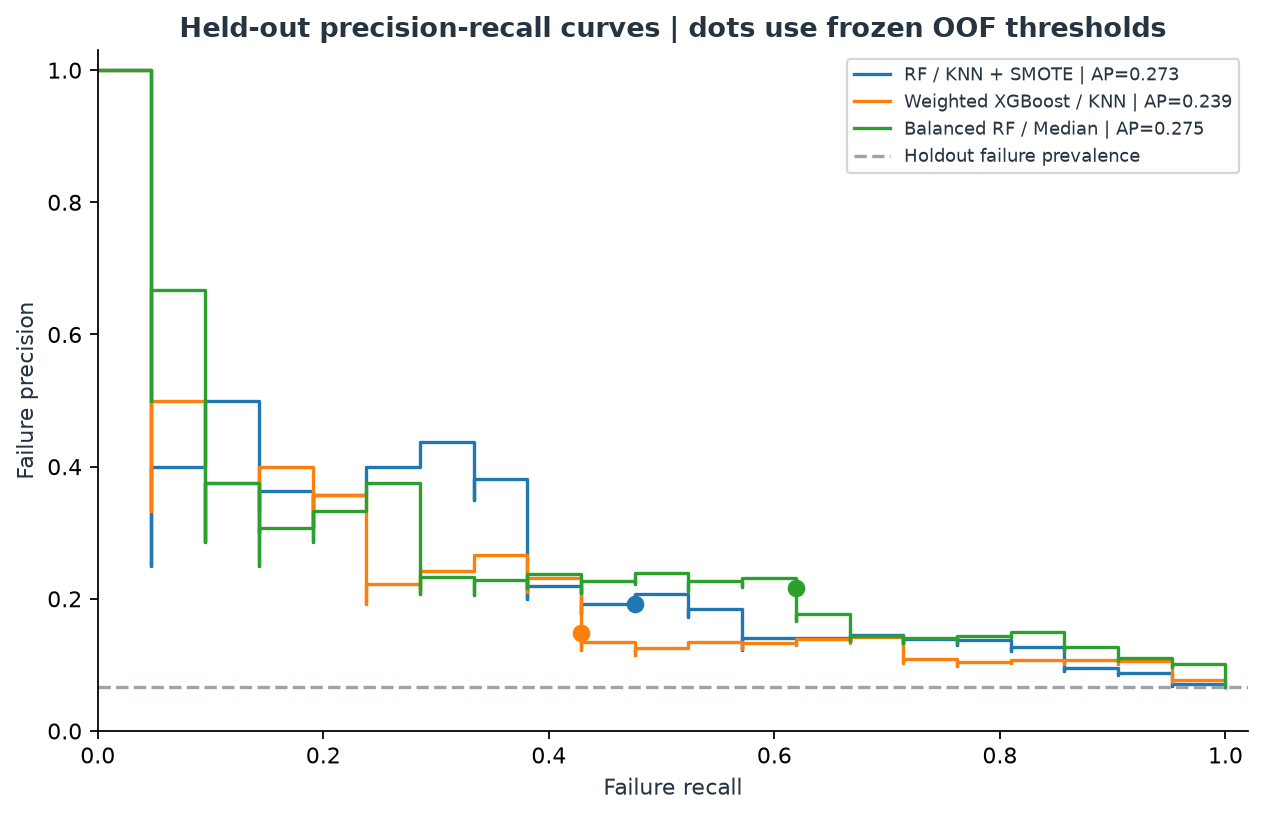

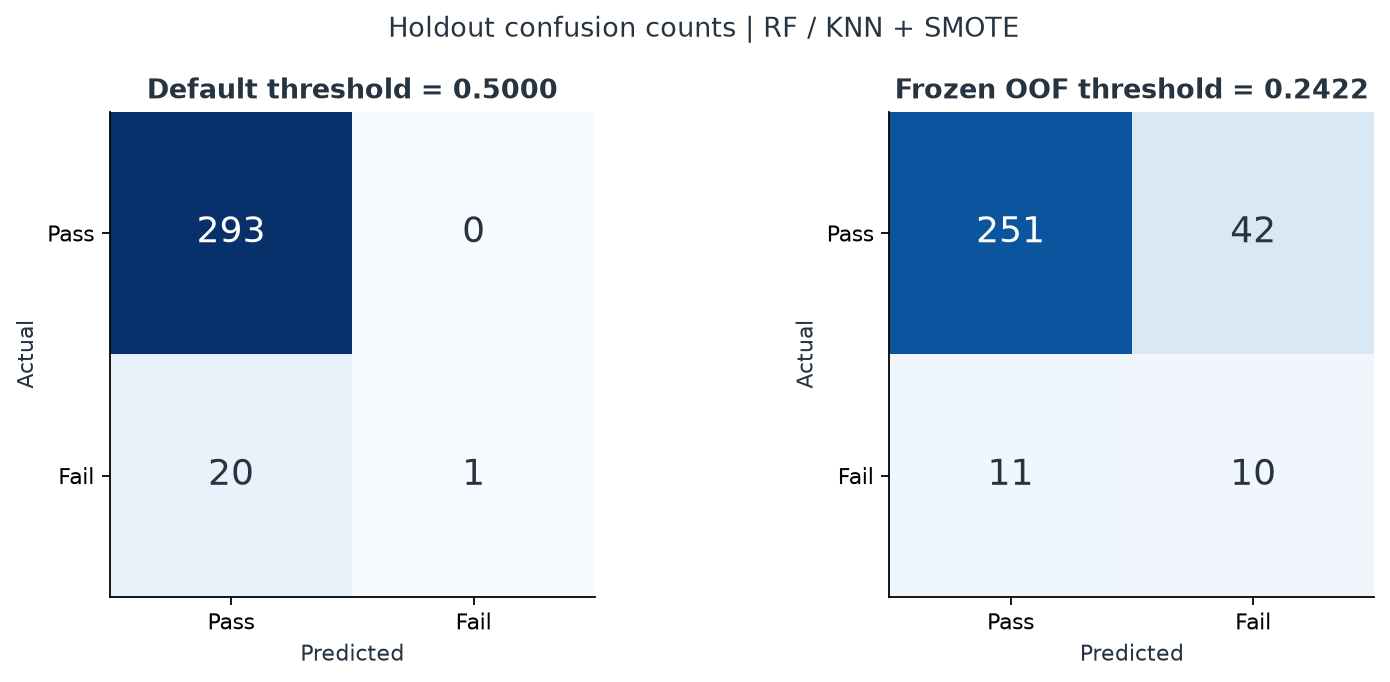

In [13]:
display(Markdown(
    'The PR curves below describe ranking on the holdout; their dots use development-frozen thresholds. '
    'The second figure compares 0.5 with the frozen threshold for the actual CV-selected candidate. '
    'The curve is not used to move either dot after observing holdout labels.'
))
display(IPythonImage(filename=str(ROOT / 'images' / 'pr_curve.png'), width=850))
display(IPythonImage(filename=str(ROOT / 'images' / 'confusion_matrix.png'), width=900))

## 8. Does the random-split story survive a narrower time question?

A stratified random holdout can mix earlier and later observations. The study therefore includes a separate, predeclared **development-only XGBoost sensitivity check**, regardless of which model wins the main comparison. The earlier 80% of development timestamps supplies three expanding-window folds for its threshold. A refit on that earlier block is evaluated on the later block, with equal timestamps kept off opposite sides of a boundary.

The initial training prefix has no forward OOF prediction and is not filled with training scores. This is a fixed-candidate sensitivity analysis, not another seven-model competition, a factory deployment simulation, or a new independent test. These development rows also participate in the main study, and the development time order can skip source observations reserved for the main holdout.

In [14]:
temporal = metrics['temporal_sensitivity']
assert bool(temporal) == protocol['config']['temporal_check']
if temporal is not None:
    assert temporal['candidate'] == 'xgb_knn'
    temporal_predictions = read_table('temporal_predictions.csv').set_index('row_id')
    assert temporal_predictions.index.is_unique
    assert set(temporal_predictions.index).issubset(set(development_ids))
    assert not set(temporal_predictions.index).intersection(holdout_ids)
    np.testing.assert_array_equal(temporal_predictions['label'], split.loc[temporal_predictions.index, 'label'])
    assert np.isfinite(temporal_predictions['score']).all()
    assert temporal_predictions['score'].between(0, 1).all()
    assert len(temporal_predictions) == temporal['later_rows']
    assert int(temporal_predictions['label'].sum()) == temporal['later_failures']
    assert temporal['early_rows'] + temporal['later_rows'] == len(y_dev)
    assert temporal['early_failures'] + temporal['later_failures'] == int(y_dev.sum())
    assert pd.Timestamp(temporal['last_training_timestamp']) < pd.Timestamp(temporal['first_validation_timestamp'])
    assert pd.to_datetime(split.loc[temporal_predictions.index, 'timestamp']).min() == pd.Timestamp(temporal['first_validation_timestamp'])
    assert_close(average_precision_score(temporal_predictions['label'], temporal_predictions['score']), temporal['average_precision'])
    assert_close(roc_auc_score(temporal_predictions['label'], temporal_predictions['score']), temporal['roc_auc'])
    assert_close(temporal_predictions['label'].mean(), temporal['failure_prevalence'])
    for policy, cutoff in [('default', 0.5), ('selected', temporal['selected']['threshold'])]:
        for key, value in reconstruct_operating(temporal_predictions['label'], temporal_predictions['score'], cutoff).items():
            assert_close(value, temporal[policy][key])
    display(pd.Series({key: temporal[key] for key in [
        'candidate', 'early_rows', 'early_failures', 'later_rows', 'later_failures',
        'last_training_timestamp', 'first_validation_timestamp', 'average_precision', 'failure_prevalence',
    ]}, name='Saved development-only chronological check').to_frame())
    display(pd.DataFrame({policy: temporal[policy] for policy in ('default', 'selected')}).T[operating_columns])
    display(Markdown(
        f'Later-development AP is **{temporal["average_precision"]:.4f}** against prevalence '
        f'**{temporal["failure_prevalence"]:.4f}**. The forward-OOF threshold is '
        f'**{temporal["selected"]["threshold"]:.6f}**. This estimate has a different training size and '
        'evaluation population from the random holdout, so their difference does not isolate a drift mechanism.'
    ))
else:
    display(Markdown('The saved configuration explicitly omits the chronological check (`temporal_check=False`); no time-transfer result is inferred.'))

,Saved development-only chronological check
candidate,xgb_knn
early_rows,1002
early_failures,69
later_rows,251
later_failures,14
last_training_timestamp,2008-10-02T19:25:00
first_validation_timestamp,2008-10-02T21:32:00
average_precision,0.09665
failure_prevalence,0.05578


,threshold,precision,recall,f1,alarm_count,true_positives,false_negatives,false_positives
default,0.5,0.0,0.0,0.0,0,0,14,0
selected,0.26711,0.0,0.0,0.0,3,0,14,3


Later-development AP is **0.0967** against prevalence **0.0558**. The forward-OOF threshold is **0.267113**. This estimate has a different training size and evaluation population from the random holdout, so their difference does not isolate a drift mechanism.

## 9. Which anonymous sensors would I investigate next?

The saved importance export is specifically **XGBoost's normalized mean split gain from the full-development fit**. It is not automatically an explanation of the selected candidate. I join it to development missingness to keep data quality visible. Correlated sensors can share or substitute importance; an anonymous ID does not establish a process mechanism.

A high-gain sensor is a question for a domain expert, not proof of causality, a dead sensor, or a validated reduced-feature detector. No top-k sensor model is fitted or evaluated in this notebook.

In [15]:
assert importance['sensor'].is_unique
assert set(importance['sensor']) == set(sensor_filter.get_feature_names_out())
assert np.isfinite(importance['gain_importance']).all()
assert importance['gain_importance'].ge(0).all()
assert importance['gain_importance'].is_monotonic_decreasing
np.testing.assert_allclose(importance['gain_importance'].sum(), 1.0, rtol=1e-5)
display(importance.head(10).set_index('sensor').join(quality[['development_missing_fraction', 'development_distinct_observed_values']]))
display(Markdown(
    f'This table describes `xgb_knn`; the frozen main choice is **`{selected}`**. '
    'It records how one fitted boosting model used the retained sensors, not what physically caused a failure.'
))

,gain_importance,development_missing_fraction,development_distinct_observed_values
sensor,,,
sensor_028,0.01345,0.00160,776
sensor_571,0.01310,0.00000,696
sensor_059,0.01292,0.00479,1211
sensor_361,0.01139,0.00000,854
sensor_196,0.01131,0.00479,757
sensor_423,0.01044,0.00239,1249
sensor_048,0.01019,0.00080,1210
sensor_153,0.01011,0.00239,209
sensor_124,0.01002,0.00479,59


This table describes `xgb_knn`; the frozen main choice is **`rf_knn_smote`**. It records how one fitted boosting model used the retained sensors, not what physically caused a failure.

## 10. What I can defend, and what I would need next

The defensible outcome is a reproducible comparison under a stated boundary, with the actual selected candidate, a development-frozen threshold, and auditable confusion counts. The original question survives: ranking, default-threshold failure detection, and a useful alarm policy are different things. The results above decide which attempted changes help under this particular protocol.

- **Previous exploration:** this public dataset and its earlier test outputs were already inspected. The new within-run holdout boundary does not erase that history. Old test-tuned F1 and current frozen F1 are not a clean before/after model experiment.
- **Small failure support:** a single random split and five overlapping training folds leave substantial uncertainty. Selection and threshold optimization also use development labels; maximum OOF F1 is not an independent estimate.
- **Dependence and transfer:** a random split does not separate lots, tools, or time. The available anonymous sensors cannot resolve all group dependence; the chronological check is descriptive. Future process conditions and failure prevalence can change precision and workload.
- **Missingness:** the mask and imputers are declared statistical choices. I have not established the missing-data mechanism, recovered ground-truth missing values, or diagnosed equipment faults.
- **Mechanisms:** PCA and SMOTE comparisons test specific pipelines. Neither dimensionality nor a poor thresholded score proves why a method succeeded or failed.
- **Scores and cost:** the scores are not calibrated physical failure probabilities. Class weights are not measured monetary costs; F1 does not establish yield savings, acceptable alarm burden, or production reliability. No factory deployment or business return is claimed.
- **Interpretability:** gain rankings from development training are associations within one fitted model. There is no causal attribution, stability analysis, independently validated sensor shortlist, or reduced-model result here.

My next credible evidence would be a genuinely new, time-separated dataset with lot/tool context and an agreed review-capacity or error-cost policy. That would let me evaluate transfer and an operating rule without reopening this holdout for another round of tuning. Calibration or feature reduction would need its own development procedure and later evaluation.

The complete generated record is [results/RESULTS.md](results/RESULTS.md), [metrics.json](results/metrics.json), and [protocol.json](results/protocol.json). The saved split, OOF and holdout predictions, fold summaries, data-quality table, and importance table make the displayed checks repeatable. Model fitting and figure generation remain in `main.py` and `secom/`; this notebook supplies the investigation and its metric audit.

In [16]:
# Catch source/protocol changes during a notebook run before saving successful outputs.
assert (RESULTS / 'protocol.json').read_bytes() == protocol_bytes
final_source_digest = sha256()
for path in source_files:
    final_source_digest.update(path.relative_to(ROOT).as_posix().encode())
    final_source_digest.update(path.read_bytes())
assert final_source_digest.hexdigest() == metrics['source_sha256']
display(Markdown(
    f'**My takeaway from this saved run:** development AP selects **{LABELS[selected]}**. '
    f'Its frozen holdout AP is **{selected_result["average_precision"]:.4f}** versus the constant-score '
    f'prevalence baseline **{selected_result["failure_prevalence"]:.4f}**. '
    f'F1 is **{selected_result["default"]["f1"]:.4f}** at 0.5 and **{chosen["f1"]:.4f}** at the '
    f'development-frozen threshold, with **{chosen["alarm_count"]} alarms** and '
    f'**{chosen["false_negatives"]} missed failures**. '
    'Those counts state the observed tradeoff; they do not establish that the policy is acceptable in a factory. '
    'All displayed development and holdout point metrics have been reconstructed from the saved predictions.'
))

**My takeaway from this saved run:** development AP selects **RF / KNN + SMOTE**. Its frozen holdout AP is **0.2727** versus the constant-score prevalence baseline **0.0669**. F1 is **0.0909** at 0.5 and **0.2740** at the development-frozen threshold, with **52 alarms** and **11 missed failures**. Those counts state the observed tradeoff; they do not establish that the policy is acceptable in a factory. All displayed development and holdout point metrics have been reconstructed from the saved predictions.